# Section 1: Dataset

The dataset I selected contains the 2025 competition results of the game *League of Legends*. I chose this dataset because I am an enthusiastic fan of the game and regularly follow its professional tournaments. This makes the dataset personally meaningful to me, as it allows me to explore and analyze the performance of the teams and players I admire through a data-driven lens. I obtained the competition data from the official event website using the link provided in the project resources. Through this analysis, I hope to identify patterns in team strategies, uncover player strengths, and gain a deeper understanding of the factors that contribute to success in professional *League of Legends* competitions.

I stored this dataset into ```df```:

In [1]:
import pandas as pd
df = pd.read_csv("2025_LoL_esports_match_data_from_OraclesElixir.csv", low_memory = False)
df

,gameid,datacompleteness,url,league,year,split,playoffs,date,game,patch,...,opp_csat25,golddiffat25,xpdiffat25,csdiffat25,killsat25,assistsat25,deathsat25,opp_killsat25,opp_assistsat25,opp_deathsat25
0,LOLTMNT03_179647,complete,NaN,LFL2,2025,Winter,0,2025-01-11 11:11:24,1,15.01,...,200.0,224.0,-1.0,17.0,1.0,1.0,2.0,2.0,4.0,2.0
1,LOLTMNT03_179647,complete,NaN,LFL2,2025,Winter,0,2025-01-11 11:11:24,1,15.01,...,157.0,-2363.0,-1444.0,-18.0,0.0,1.0,2.0,1.0,7.0,0.0
2,LOLTMNT03_179647,complete,NaN,LFL2,2025,Winter,0,2025-01-11 11:11:24,1,15.01,...,241.0,-1552.0,-2465.0,-41.0,1.0,0.0,2.0,1.0,5.0,1.0
3,LOLTMNT03_179647,complete,NaN,LFL2,2025,Winter,0,2025-01-11 11:11:24,1,15.01,...,257.0,-2613.0,-1156.0,-6.0,1.0,1.0,2.0,6.0,2.0,0.0
4,LOLTMNT03_179647,complete,NaN,LFL2,2025,Winter,0,2025-01-11 11:11:24,1,15.01,...,20.0,-662.0,-734.0,18.0,0.0,2.0,2.0,0.0,8.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118327,LOLTMNT04_135955,complete,NaN,EM,2025,Summer,0,2025-11-02 20:18:14,3,15.20,...,230.0,-621.0,-2339.0,-14.0,1.0,4.0,2.0,1.0,2.0,2.0
118328,LOLTMNT04_135955,complete,NaN,EM,2025,Summer,0,2025-11-02 20:18:14,3,15.20,...,235.0,1038.0,-172.0,34.0,4.0,3.0,1.0,2.0,3.0,0.0
118329,LOLTMNT04_135955,complete,NaN,EM,2025,Summer,0,2025-11-02 20:18:14,3,15.20,...,32.0,519.0,-1238.0,8.0,1.0,8.0,0.0,0.0,3.0,3.0
118330,LOLTMNT04_135955,complete,NaN,EM,2025,Summer,0,2025-11-02 20:18:14,3,15.20,...,935.0,-2310.0,3279.0,-50.0,6.0,12.0,10.0,10.0,25.0,6.0


The dataset is quite large, containing ```118332``` rows and ```164``` columns that record all competition information from the year 2025. However, many of these columns provide little value for analysis — for instance, the year column, since all entries are already from 2025. Therefore, I filtered out the most relevant columns and stored them in a new DataFrame named ```df_important```. Due to our focus on analyzing individual players, data belongs to teams will be excluded.

In [2]:
important_columns = ['league','teamname','playername','side','champion','position','gamelength','kills','deaths','assists','damagetochampions','dpm','totalgold','earned gpm']
df_important = df[important_columns]
df_important = df_important[df_important.position != "team"].reset_index()
df_important

,index,league,teamname,playername,side,champion,position,gamelength,kills,deaths,assists,damagetochampions,dpm,totalgold,earned gpm
0,0,LFL2,IziDream,PatkicaA,Blue,Gnar,top,1592,1,2,1,20156,759.6482,10668,269.2839
1,1,LFL2,IziDream,Joinze,Blue,Maokai,jng,1592,0,3,1,4963,187.0477,7429,147.2111
2,2,LFL2,IziDream,Sayn,Blue,Hwei,mid,1592,1,2,0,13952,525.8291,9032,207.6256
3,3,LFL2,IziDream,Shiganari,Blue,Jinx,bot,1592,1,3,1,6898,259.9749,9407,221.7588
4,4,LFL2,IziDream,Lekcyc,Blue,Leona,sup,1592,0,3,2,4174,157.3116,5719,82.7638
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98605,118325,EM,Los Heretics,Tracyn,Red,Renekton,top,2090,6,6,8,28450,816.7464,14603,288.9187
98606,118326,EM,Los Heretics,Daglas,Red,Trundle,jng,2090,3,3,12,18527,531.8756,12384,225.2153
98607,118327,EM,Los Heretics,Mercy9,Red,Akali,mid,2090,5,5,7,27203,780.9474,13164,247.6077
98608,118328,EM,Los Heretics,Rin,Red,Sivir,bot,2090,4,5,9,26517,761.2536,15278,308.2967


---

# Section 2: EDA

Among all the teams, ```T1``` is my favorite. I am particularly interested in analyzing how its players performed throughout the competition. To focus my analysis, I filtered the dataset to include only the matches that involved ```T1``` and stored this subset in a new DataFrame named ```df_T1```. This allows for a more detailed examination of the team’s strategies, player statistics, and overall consistency across different stages of the event.


In [3]:
df_T1 = df_important[df_important["teamname"] == "T1"].reset_index()
df_T1

,level_0,index,league,teamname,playername,side,champion,position,gamelength,kills,deaths,assists,damagetochampions,dpm,totalgold,earned gpm
0,665,797,LCK,T1,Doran,Red,Gragas,top,1404,0,1,0,7590,324.3590,8009,208.0769
1,666,798,LCK,T1,Oner,Red,Zyra,jng,1404,1,3,0,6972,297.9487,7541,188.0769
2,667,799,LCK,T1,Faker,Red,Yone,mid,1404,0,2,0,8732,373.1624,7956,205.8120
3,668,800,LCK,T1,Gumayusi,Red,Ashe,bot,1404,1,4,1,9136,390.4274,8552,231.2821
4,669,801,LCK,T1,Keria,Red,Rell,sup,1404,0,4,2,3850,164.5299,4764,69.4017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
815,98575,118289,WLDs,T1,Doran,Red,Sion,top,1735,7,3,15,30904,1068.7262,13072,320.1268
816,98576,118290,WLDs,T1,Oner,Red,Pantheon,jng,1735,12,2,9,27925,965.7061,14146,357.2680
817,98577,118291,WLDs,T1,Faker,Red,Mel,mid,1735,8,4,10,25526,882.7435,12745,308.8184
818,98578,118292,WLDs,T1,Gumayusi,Red,Ashe,bot,1735,6,4,18,26270,908.4726,12909,314.4899


In the game, there is a concept called the *damage conversion rate*, which measures how effectively a player can convert their in-game economic resources into actual damage output. To analyze this, I calculated the damage conversion rate for each member of the T1 team in each game and stored the results in a new column named ```dcr```, sorted in descending order.

In [4]:
df_T1["dcr"] = df_T1["damagetochampions"] / df_T1["totalgold"]
df_T1.sort_values(by = "dcr", ascending = False)

,level_0,index,league,teamname,playername,side,champion,position,gamelength,kills,deaths,assists,damagetochampions,dpm,totalgold,earned gpm,dcr
360,62650,75180,MSI,T1,Doran,Blue,Rumble,top,2283,10,6,17,49503,1300.9987,15741,284.0473,3.144845
33,2718,3260,LCK,T1,Smash,Red,Ezreal,bot,2359,8,2,2,53361,1357.2107,17576,317.6261,3.036015
403,62943,75531,MSI,T1,Gumayusi,Blue,Corki,bot,2751,11,2,5,65067,1419.1276,22791,368.6587,2.854943
618,82858,99428,LCK,T1,Gumayusi,Red,Corki,bot,2829,6,3,9,59487,1261.6543,20874,314.4645,2.849813
602,81727,98071,LCK,T1,Faker,Red,Orianna,mid,2489,4,6,9,41970,1011.7316,14945,231.2254,2.808297
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
184,35939,43125,LCK,T1,Keria,Red,Rakan,sup,1633,0,5,1,2199,80.7961,5580,72.4923,0.394086
19,999,1197,LCK,T1,Keria,Red,Rakan,sup,2046,1,4,17,3486,102.2287,9138,137.5073,0.381484
39,2744,3292,LCK,T1,Keria,Blue,Rakan,sup,1710,1,0,14,2973,104.3158,8291,158.8421,0.358582
299,53784,64540,LCK,T1,Keria,Blue,Alistar,sup,2070,0,2,3,2446,70.8986,6874,68.8696,0.355834


It appears that the support role tends to have a lower damage conversion rate compared to other positions, which makes sense given its primary focus on providing vision control, protection, and utility rather than direct damage output. To verify this assumption, I calculated the average DCR for each position and compare the results to see how role differences influence damage efficiency.

In [5]:
df_T1.groupby("position").agg("mean", numeric_only = True).sort_values(by = "dcr")

,level_0,index,gamelength,kills,deaths,assists,damagetochampions,dpm,totalgold,earned gpm,dcr
position,,,,,,,,,,,
sup,58846.682927,70614.670732,1928.384146,0.841463,2.817073,11.634146,7941.993902,249.946741,8215.920732,125.715818,0.963201
jng,58843.682927,70611.670732,1928.384146,3.957317,2.670732,8.067073,15796.762195,494.300710,12412.109756,257.521928,1.253406
top,58842.682927,70610.670732,1928.384146,2.884146,3.268293,6.487805,19818.737805,619.267276,12647.957317,263.393385,1.559988
mid,58844.682927,70612.670732,1928.384146,3.384146,2.420732,7.115854,22034.451220,684.318194,13104.945122,277.432284,1.665578
bot,58845.682927,70613.670732,1928.384146,5.250000,2.237805,6.317073,25366.609756,778.842176,14824.262195,330.351898,1.680295


According to the results, the support position indeed has the lowest average damage conversion rate (```0.96```), confirming our initial assumption. This aligns with the nature of the support role, which focuses more on assisting teammates rather than dealing damage directly. In contrast, carries such as the mid and bot positions show significantly higher DCR values (around ```1.66```–```1.68```), indicating their stronger efficiency in turning gold income into damage output. Overall, the analysis highlights how role specialization in the game naturally shapes each player’s contribution to team damage.

---

# Section 3: Visualization

Among all the members of T1, **Faker** is undoubtedly the strongest — often regarded by fans as a near god-like figure in the world of League of Legends. Having led his team to five world championship titles, his dominance is unquestionable. What intrigues me, however, is the choice of champions he used to achieve such success. To explore this, I filtered all match records involving **Faker**, stored them in a new DataFrame called ```df_Faker```, and grouped the data based on the champions he played into the DataFrame ```df_champion```.

In [6]:
df_Faker = df_T1[df_T1.playername == "Faker"]
df_Faker

,level_0,index,league,teamname,playername,side,champion,position,gamelength,kills,deaths,assists,damagetochampions,dpm,totalgold,earned gpm,dcr
2,667,799,LCK,T1,Faker,Red,Yone,mid,1404,0,2,0,8732,373.1624,7956,205.8120,1.097536
7,682,818,LCK,T1,Faker,Blue,Viktor,mid,1909,3,1,8,33122,1041.0267,15035,341.4877,2.202993
12,697,835,LCK,T1,Faker,Red,Azir,mid,2044,1,4,3,24731,725.9589,13084,253.5910,1.890171
17,997,1195,LCK,T1,Faker,Red,Galio,mid,2046,5,2,14,30274,887.8006,14553,296.3050,2.080258
22,1017,1219,LCK,T1,Faker,Red,Aurora,mid,1697,3,1,4,15600,551.5616,11470,273.4119,1.360070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
797,98262,117914,WLDs,T1,Faker,Blue,Viktor,mid,2192,7,2,12,32063,877.6369,16530,322.5274,1.939685
802,98277,117931,WLDs,T1,Faker,Red,Mel,mid,2115,6,3,2,29238,829.4468,14367,277.3617,2.035080
807,98552,118262,WLDs,T1,Faker,Blue,Orianna,mid,1812,6,0,5,27975,926.3245,14294,341.7881,1.957115
812,98567,118279,WLDs,T1,Faker,Red,Galio,mid,1630,4,1,14,16774,617.4479,12030,310.2699,1.394347


In [7]:
df_champion = df_Faker.groupby("champion").agg("count").reset_index()
df_champion = df_champion.sort_values(by = "index", ascending = False)
df_champion

,champion,level_0,index,league,teamname,playername,side,position,gamelength,kills,deaths,assists,damagetochampions,dpm,totalgold,earned gpm,dcr
19,Viktor,24,24,24,24,24,24,24,24,24,24,24,24,24,24,24,24
13,Orianna,18,18,18,18,18,18,18,18,18,18,18,18,18,18,18,18
14,Ryze,18,18,18,18,18,18,18,18,18,18,18,18,18,18,18,18
9,Galio,17,17,17,17,17,17,17,17,17,17,17,17,17,17,17,17
6,Azir,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16,16
17,Taliyah,14,14,14,14,14,14,14,14,14,14,14,14,14,14,14,14
0,Ahri,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10,10
4,Annie,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
16,Sylas,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
5,Aurora,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5,5


Now it is time to bring the data to life through visualization! By plotting the results, we can more intuitively observe patterns in Faker’s champion usage and performance, making it easier to identify which champions contributed most to his victories and overall dominance in the competition.

<Axes: title={'center': "Faker's most commonly used champions"}, xlabel='Champion', ylabel='Frequency'>

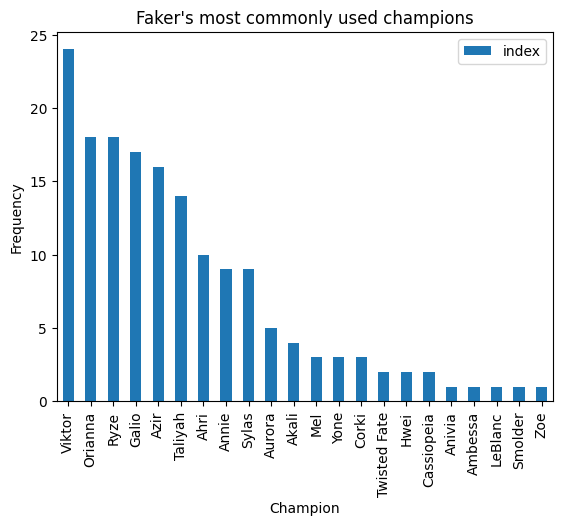

In [8]:
df_champion.plot.bar(x = "champion", y = "index", xlabel = "Champion", ylabel = "Frequency", title = "Faker's most commonly used champions")

From the visualization, it is clear that **Faker** tends to favor control mages such as ```Viktor```, ```Orianna```, ```Ryze```, ```Galio```, and ```Azir```, which aligns with his reputation for strategic and methodical gameplay. These champions excel at wave control, teamfight coordination, and map presence — qualities that perfectly complement Faker’s role as the team’s tactical core. His consistent choice of these champions reflects not only his mastery of macro play and decision-making but also his ability to adapt and lead ```T1``` through different game metas. Even when occasionally picking more aggressive or unconventional champions, Faker’s champion pool demonstrates both versatility and a deep understanding of how to shape the game’s tempo to his advantage.

---

# Section 4: Planning for Part II

When I analyzed the dataset, I realized that using a single metric is not enough to accurately capture a player’s overall contribution in the competition. For instance, the previously calculated Damage Conversion Rate (DCR) shows relatively low values for players in the support role, but this does not necessarily indicate poor performance. On the contrary, supports often contribute in ways that are not reflected in damage-based statistics，such as providing vision control, initiating key plays, and protecting teammates during critical moments. These forms of utility are essential to a team’s success, even if they don’t directly translate into high damage numbers.

Therefore, in the next stage of my analysis, I plan to develop a more comprehensive evaluation metric that integrates multiple aspects of gameplay performance. This could include variables like vision score, crowd control duration, assist ratio, and objective participation, alongside traditional indicators such as DCR and gold efficiency. By combining these different dimensions, I hope to construct a more balanced model that better reflects each player’s true impact within their team.

---

# Section 5: Data Science

In the fourth part of the project, I originally planned to develop an overall rating system to evaluate players’ contributions in a given competition. However, after further research, I realized that this goal is difficult to achieve. The official scoring algorithm used in professional League of Legends matches is not publicly available, and historical player ratings are not included in the dataset. As a result, any rating based solely on my personal judgment would introduce significant bias. Therefore, I have decided to shift my focus and investigate a different research question.

Finally, I chose to examine the relationship between players’ kills, deaths, assists, and the amount of gold they earn per point. In League of Legends, kills and assists directly contribute to gold income, while avoiding death enables players to remain on the map and continue accumulating resources. These mechanics make the interactions among these variables both meaningful and relevant for analysis. A reasonable hypothesis is that players who secure more kills and assists — and die less frequently — will generally achieve higher gold efficiency. In the following analysis, I will evaluate this hypothesis using the dataset to determine whether the data supports this relationship.

To pursue this goal, I will use the previously collected competition data from ```T1``` to build a linear regression model called ```model```. I will then apply this model to predict the performance of other teams and compare the predictions with their actual results to evaluate the model’s validity.

In [10]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
ind = ['kills','deaths','assists']
dep = 'earned gpm'
model.fit(df_T1[ind],df_T1[dep])

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Now that the model has been built, we can test it using the match results of another team ```WBG```. The first step is to filter out all records related to ```WBG``` and store them in a new dataset, ```df_WBG```.

In [11]:
df_WBG = df_important[df_important["teamname"] == "Weibo Gaming"].reset_index()
df_WBG

,level_0,index,league,teamname,playername,side,champion,position,gamelength,kills,deaths,assists,damagetochampions,dpm,totalgold,earned gpm
0,40,48,LPL,Weibo Gaming,Breathe,Blue,K'Sante,top,2123,4,0,3,9830,277.8144,14706,285.4169
1,41,49,LPL,Weibo Gaming,Tian,Blue,Viego,jng,2123,4,0,5,10013,282.9863,14586,282.0254
2,42,50,LPL,Weibo Gaming,Xiaohu,Blue,Aurora,mid,2123,5,1,8,37571,1061.8276,15720,314.0744
3,43,51,LPL,Weibo Gaming,Light,Blue,Ashe,bot,2123,3,2,6,15603,440.9703,14688,284.9081
4,44,52,LPL,Weibo Gaming,Hang,Blue,Braum,sup,2123,1,2,11,6292,177.8238,9762,145.6901
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,96150,115380,ASI,Weibo Gaming,Breathe,Blue,Ornn,top,1825,2,5,8,13724,451.2000,9764,189.5342
746,96151,115381,ASI,Weibo Gaming,Tian,Blue,Wukong,jng,1825,5,6,8,16291,535.5945,12083,265.7753
747,96152,115382,ASI,Weibo Gaming,Xiaohu,Blue,LeBlanc,mid,1825,7,3,8,27809,914.2685,13422,309.7973
748,96153,115383,ASI,Weibo Gaming,Light,Blue,Xayah,bot,1825,1,4,8,29586,972.6904,10810,223.9233


Next, we store the model’s predicted values in a new column named ```predicted gpm```, and then calculate the ```residual```, to see if the model fits well.

In [15]:
df_WBG["predicted gpm"] = model.predict(df_WBG[ind])
df_WBG["residual"] = df_WBG["earned gpm"] - df_WBG["predicted gpm"]
df_WBG

,level_0,index,league,teamname,playername,side,champion,position,gamelength,kills,deaths,assists,damagetochampions,dpm,totalgold,earned gpm,predicted gpm,residual
0,40,48,LPL,Weibo Gaming,Breathe,Blue,K'Sante,top,2123,4,0,3,9830,277.8144,14706,285.4169,302.460455,-17.043555
1,41,49,LPL,Weibo Gaming,Tian,Blue,Viego,jng,2123,4,0,5,10013,282.9863,14586,282.0254,297.587025,-15.561625
2,42,50,LPL,Weibo Gaming,Xiaohu,Blue,Aurora,mid,2123,5,1,8,37571,1061.8276,15720,314.0744,301.766967,12.307433
3,43,51,LPL,Weibo Gaming,Light,Blue,Ashe,bot,2123,3,2,6,15603,440.9703,14688,284.9081,256.362797,28.545303
4,44,52,LPL,Weibo Gaming,Hang,Blue,Braum,sup,2123,1,2,11,6292,177.8238,9762,145.6901,203.000766,-57.310666
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,96150,115380,ASI,Weibo Gaming,Breathe,Blue,Ornn,top,1825,2,5,8,13724,451.2000,9764,189.5342,203.602712,-14.068512
746,96151,115381,ASI,Weibo Gaming,Tian,Blue,Wukong,jng,1825,5,6,8,16291,535.5945,12083,265.7753,256.271255,9.504045
747,96152,115382,ASI,Weibo Gaming,Xiaohu,Blue,LeBlanc,mid,1825,7,3,8,27809,914.2685,13422,309.7973,324.747139,-14.949839
748,96153,115383,ASI,Weibo Gaming,Light,Blue,Xayah,bot,1825,1,4,8,29586,972.6904,10810,223.9233,192.112625,31.810675


From the results, we can see that aside from a few outliers with larger discrepancies, the model’s predictions align well with the actual data. In general, players with more kills and assists — and fewer deaths — tend to achieve higher average gold per minute, which is consistent with expectations.

---

# Section 6: A Different Data Visualization

```T1``` is a South Korean team, while ```WBG``` represents China in the League of Legends competitive scene. These two teams are known for having distinct strategic approaches and pacing styles during matches. To explore these stylistic differences, I compared their average match durations using a boxplot visualization of their game length data.

<Axes: title={'center': 'Game Length Comparison: T1 vs WBG'}, ylabel='Game Length'>

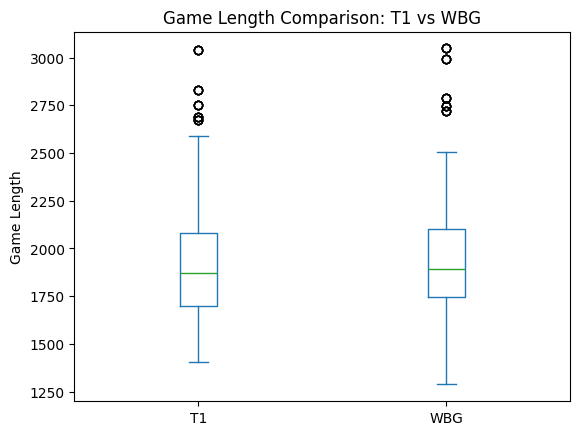

In [20]:
df_compare = pd.DataFrame({"T1": df_T1["gamelength"], "WBG": df_WBG["gamelength"]})
df_compare.plot.box(title="Game Length Comparison: T1 vs WBG", ylabel="Game Length")

The visualization shows clear differences between the two teams. ```T1```’s matches tend to be slightly shorter and more concentrated around the median, suggesting a more consistent pacing and possibly a more controlled playstyle. ```WBG```’s match durations show a wider range and more variability, which may reflect a more volatile or flexible playstyle that leads to both shorter and longer games. Additionally, both teams display a set of outliers, indicating that each occasionally participates in unusually long matches.

Overall, the boxplot comparison highlights how match duration can serve as a useful indicator of stylistic tendencies, with ```T1``` generally playing faster and more consistently, while ```WBG``` exhibits more variation in game length.

---

# Section 7: Overall Summary

The dataset I worked with contains ```118332``` rows of match records from the 2025 League of Legends competitive season. Using this large dataset, I explored multiple aspects of team and player performance, beginning with my favorite team, ```T1```, and later extending the analysis to other teams such as ```WBG```. Through exploratory data analysis, I examined key gameplay metrics including kill/death/assist statistics, gold efficiency, and a performance measure I calculated — the Damage Conversion Rate (DCR). One notable early finding was that support players consistently showed the lowest DCR values among all roles, which aligns with their in-game responsibilities and lower damage output.

I then focused on **Faker**, one of ```T1```’s core players, and visualized his champion usage and performance patterns. The visualizations showed that Faker favored specific champions and maintained strong performance consistency across them, highlighting how his champion pool contributes to ```T1```’s overall strength. In the Data Science portion of the project, I constructed a linear regression model using ```T1```’s match data to analyze how kills, deaths, and assists influence gold earned per minute. When tested on ```WBG``` match data, the model performed reasonably well, showing only a few outliers while most predictions closely matched actual gold values. This supported the hypothesis that more kills and assists — and fewer deaths — lead to higher gold efficiency. Finally, to compare team-level strategic differences, I created a boxplot of match durations for ```T1``` and ```WBG```. The visualization revealed that ```T1```’s games cluster around a consistent median, while ```WBG```’s durations show greater variability, indicating different styles of play. Together, these findings demonstrate how data science can uncover meaningful patterns in competitive gaming and provide insight into team strategy and player performance.